In [74]:
import pandas as pd

In [75]:
movies= pd.read_csv("data/movies.csv")
ratings= pd.read_csv("data/ratings.csv")

print("Movies:")
display(movies.head())   #show first 5 movies
print("Ratings:")
display(ratings.head())         #show first 5 ratings

Movies:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Ratings:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [76]:
display(movies.isnull().sum())      #check missing value in movies
display(ratings.isnull().sum())     #check missing value in ratings
display(movies.duplicated().sum())       #count duplicate rows in movies
display(ratings.duplicated().sum())         #in ratings

movieId    0
title      0
genres     0
dtype: int64

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

np.int64(0)

np.int64(0)

In [77]:
ratings["rating"].value_counts().sort_index()       #count how many times each rating appears (arranges them from 0.5 to 5.0)

rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

we got 4.0 stars the most (26818 ratings), then 3.0 stars(20047)

In [78]:
#create Like and Not Like 
#Like(1)- rating >= 4.0 and Not Like(0)- rating below 4.0
#with that machine learning models can predict whether a user likes a movie or not

ratings["liked"] = (ratings["rating"]>=4.0).astype(int)     #1= like, 0= not like
display(ratings.head())         #now show new liked column

,userId,movieId,rating,timestamp,liked
0,1,1,4.0,964982703,1
1,1,3,4.0,964981247,1
2,1,6,4.0,964982224,1
3,1,47,5.0,964983815,1
4,1,50,5.0,964982931,1


In [79]:
ratings["liked"].value_counts()        #count how many ratings belong to each category

liked
0    52256
1    48580
Name: count, dtype: int64

In [80]:
#since we have two separate datasets with 'movies' contains movie titles and genres, 'ratings' contains user IDs, movie IDs, ratings, and now new 'liked' column, we gonna combine them so each rating also has info about the movie

df= pd.merge(ratings, movies, on="movieId")         #combine datasets using movieId
display(df.head())

,userId,movieId,rating,timestamp,liked,title,genres
0,1,1,4.0,964982703,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,1,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,1,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,1,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,1,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


Now as I proposed in the proposal, we gonna use four features- user avg rating, movie avg rating, movie popularity, and user genre preference.

In [81]:
#for user who rating multiple movies, we gonna calculate avg to explore their rating behavior.

user_avg= df.groupby("userId")["rating"].mean()     
display(user_avg.head())

userId
1    4.366379
2    3.948276
3    2.435897
4    3.555556
5    3.636364
Name: rating, dtype: float64

so user 1 tends to give higher ratings= 4.37, user 3 tends to give lower ratings= 2.44 etc.

In [82]:
#now for movie avg rating, we gonna check how highly a movie is rated by all users who watched and rated it.

movie_avg= df.groupby("movieId")["rating"].mean()       #calculate avg rating for each movie
display(movie_avg.head())

movieId
1    3.920930
2    3.431818
3    3.259615
4    2.357143
5    3.071429
Name: rating, dtype: float64

so movie 1 toy story got 3.92 and movie 2 Jumanju got 3.43. movie avg rating shows how users generally rate a particular movie.

In [83]:
#For movie popularity, we gonna measure it by how many ratings a movie got

movie_popular= df.groupby("movieId")["rating"].count()
display(movie_popular.head())

movieId
1    215
2    110
3     52
4      7
5     49
Name: rating, dtype: int64

Toy story has 215 ratings, Jumanji- 110, Grumpier old men- 52, waiting to exhale-7, father of the bride part II - 49

In [84]:
#For user genre preference= identify what types of movies a user tend to like
#if user1 give high ratings to comedy but low ratings for horror, then user1 prefers comedy.
#first need to separate the genres because they're currently sotred together

genre_df= df.copy()         #make a copy of combined set
genre_df["genres"]= genre_df["genres"].str.split("|")       #sperate genres into a list
genre_df= genre_df.explode("genres")        #create one row for each genre
display(genre_df.head())

,userId,movieId,rating,timestamp,liked,title,genres
0,1,1,4.0,964982703,1,Toy Story (1995),Adventure
0,1,1,4.0,964982703,1,Toy Story (1995),Animation
0,1,1,4.0,964982703,1,Toy Story (1995),Children
0,1,1,4.0,964982703,1,Toy Story (1995),Comedy
0,1,1,4.0,964982703,1,Toy Story (1995),Fantasy


In [85]:
#now calculate avg rating each user gives to each genre

genre_avg= genre_df.groupby(["userId","genres"])["rating"].mean()        #avg rating for each user and genre
display(genre_avg.head())

userId  genres   
1       Action       4.322222
        Adventure    4.388235
        Animation    4.689655
        Children     4.547619
        Comedy       4.277108
Name: rating, dtype: float64

user1 gives animation rating 4.68 but comedy got 4.28 so that means, user1 tends to prefer animation over comedy.

In [86]:
df.shape        #check rows and columns after combining datasets

(100836, 7)

In [87]:
#we didn't lose any ratings when merging so now we gonna split the dataset for training 80% and testing 20%

from sklearn.model_selection import train_test_split        
train_df, test_df= train_test_split(df, test_size=0.2, random_state=42, stratify=df["liked"])
print(train_df.shape)
print(test_df.shape)

(80668, 7)
(20168, 7)


In [88]:
train_user_avg= train_df.groupby("userId")["rating"].mean()         #avg rating for each user in training data
display(train_user_avg.head())      

userId
1    4.340909
2    3.900000
3    2.166667
4    3.630682
5    3.625000
Name: rating, dtype: float64

Now user1 avg changed form 4.36 to 4.34 since we are using only the training ratings instead of entire set.

In [89]:
#this is for movie average rating from training data

train_movie_avg= train_df.groupby("movieId")["rating"].mean()
display(train_movie_avg.head())

movieId
1    3.914013
2    3.413043
3    3.337838
4    3.000000
5    2.987500
Name: rating, dtype: float64

In [90]:
#movie popularity

train_movie_popular= train_df.groupby("movieId")["rating"].count()
display(train_movie_popular.head())

movieId
1    157
2     92
3     37
4      2
5     40
Name: rating, dtype: int64

In [91]:
#user genre preference

train_genre= train_df.copy()
train_genre["genres"]= train_genre["genres"].str.split("|")        #sperate genres
train_genre= train_genre.explode("genres")
train_genre_avg= train_genre.groupby(["userId", "genres"])["rating"].mean()
display(train_genre_avg.head())

userId  genres   
1       Action       4.291667
        Adventure    4.400000
        Animation    4.590909
        Children     4.545455
        Comedy       4.261538
Name: rating, dtype: float64

In [92]:
#turn these calculated avg into columns that machine learning models can use
#user average rating

train_df["user_avg"]= train_df["userId"].map(train_user_avg)        #add each user's avg rating
display(train_df.head())

,userId,movieId,rating,timestamp,liked,title,genres,user_avg
44488,297,457,4.0,900871989,1,"Fugitive, The (1993)",Thriller,2.741379
87210,562,3825,4.0,1368896649,1,Coyote Ugly (2000),Comedy|Drama|Romance,4.121547
72377,466,76093,4.5,1439885230,1,How to Train Your Dragon (2010),Adventure|Animation|Children|Fantasy|IMAX,3.940217
81439,514,124484,3.0,1533946674,0,Kenny & Company (1976),Comedy|Drama,3.260188
10097,66,1370,3.5,1093144021,0,Die Hard 2 (1990),Action|Adventure|Thriller,4.000000


In [93]:
#fix user avg to avoid data leak

user_sum= train_df.groupby("userId")["rating"].transform("sum")         #total ratings for each user
user_count= train_df.groupby("userId")["rating"].transform("count")     #num of rating for each user

#we want user avg= (total rating scores-current rating)/num of ratings - 1
train_df["user_avg"]= (user_sum - train_df["rating"])/ (user_count - 1)         #subtract current movie's rating and subtract 1 from the count(so this calculate user's avg without including rating we're trying to predict)

In [94]:
display(train_df[["userId", "rating", "user_avg"]].head())      #check the updated user avg
print(train_df["user_avg"].isnull().sum())      #count missing user avg

,userId,rating,user_avg
44488,297,4.0,2.719298
87210,562,4.0,4.122222
72377,466,4.5,3.934066
81439,514,3.0,3.261006
10097,66,3.5,4.001845


0


In [95]:
#now user_avg values changed and missing value is 0. 
#do the same thing for movie average rating

movie_sum= train_df.groupby("movieId")["rating"].transform("sum")         
movie_count= train_df.groupby("movieId")["rating"].transform("count")    

#we want movie avg= (total rating scores-current rating)/num of ratings - 1
train_df["movie_avg"]= (movie_sum - train_df["rating"])/ (movie_count - 1) 
display(train_df[["movieId", "rating", "movie_avg"]].head())      
print(train_df["movie_avg"].isnull().sum()) 

,movieId,rating,movie_avg
44488,457,4.0,3.975694
87210,3825,4.0,2.823529
72377,76093,4.5,3.916667
81439,124484,3.0,NaN
10097,1370,3.5,3.435185


3289


some movies have only one rating in our training dataset, example- movieid 124484 that has only 3.0 rating and excluded it from the set leaves no other rating to calculate an avg, so it became NaN. 

In [96]:
#for movies without another rating, we gonna use overall avg rating from training set

overall_avg= train_df["rating"].mean()
train_df["movie_avg"]= train_df["movie_avg"].fillna(overall_avg)        #replace missing movie avg
print(train_df["movie_avg"].isnull().sum())

0


In [97]:
#for movie popularity
movie_count= train_df.groupby("movieId")["rating"].transform("count")       #count ratings for each movie
train_df["movie_popular"]= movie_count - 1
display(train_df[["movieId", "rating", "movie_popular"]].head())        #exclude current rating (for same movie with three ratings, movie popularity= 3-1=2)

,movieId,rating,movie_popular
44488,457,4.0,144
87210,3825,4.0,17
72377,76093,4.5,42
81439,124484,3.0,0
10097,1370,3.5,54


movie 457 has 144 other ratings in the training data. movie 124484 has 0 other ratings so it only has one rating in the training data.

In [98]:
# user genre preference  #want to see how much a particular user likes each movie genre based on their ratings on each genre.

train_genre["genre_avg"]= train_genre.set_index(["userId", "genres"]).index.map(train_genre_avg)        #find and retrieve the rating of combination of userId and genre then put it into genre_avg
train_genre["genre_pref"]= train_genre["genre_avg"]
display(train_genre[["userId", "genres", "genre_pref"]].head())

,userId,genres,genre_pref
44488,297,Thriller,2.666667
87210,562,Comedy,4.200000
87210,562,Drama,4.230769
87210,562,Romance,4.255556
72377,466,Adventure,3.882979


user 297 turns to give thriller movies low rating.

In [99]:
#a movie can belong to multiple genres like user 562's movie belongs to three genres. so we need to combine them into one value for that movie

genre_pref= train_genre.groupby(level=0)["genre_pref"].mean()  #we need one genre preference for each movie rating so used level=0
train_df["genre_pref"]= genre_pref      
display(train_df[["userId", "movieId", "genre_pref"]].head())  

,userId,movieId,genre_pref
44488,297,457,2.666667
87210,562,3825,4.228775
72377,466,76093,3.959020
81439,514,124484,3.468286
10097,66,1370,3.868717


completed adding all four features

In [100]:
#check any missing values
features= ["user_avg", "movie_avg", "movie_popular", "genre_pref"]
display(train_df[features].head())
print(train_df[features].isnull().sum())

,user_avg,movie_avg,movie_popular,genre_pref
44488,2.719298,3.975694,144,2.666667
87210,4.122222,2.823529,17,4.228775
72377,3.934066,3.916667,42,3.959020
81439,3.261006,3.501481,0,3.468286
10097,4.001845,3.435185,54,3.868717


user_avg         0
movie_avg        0
movie_popular    0
genre_pref       0
dtype: int64


In [101]:
overall_avg= train_df["rating"].mean()      #calculate avg rating from training data
train_df["movie_avg"]= train_df["movie_avg"].fillna(overall_avg)    #fill missing movie avg
print(train_df[features].isnull().sum())

user_avg         0
movie_avg        0
movie_popular    0
genre_pref       0
dtype: int64


In [102]:
#for user genre pref data leak

genre_sum= train_genre.groupby(["userId", "genres"])["rating"].transform("sum")     #total rating scores
genre_count= train_genre.groupby(["userId", "genres"])["rating"].transform("count")     #num of rating
train_genre["genre_pref"]= (genre_sum- train_genre["rating"])/ (genre_count-1)       #genre pref= (genre rating sum- curr rating)/(genre rating count - 1)
train_df["genre_pref"]= train_genre.groupby(level=0)["genre_pref"].mean()       #avg genres for each movie rating
print(train_df["genre_pref"].isnull().sum())

94


we got 94 missing values. That could say some users haven't rated any other movies in the genres of a particular movie. 

In [103]:
train_df["genre_pref"]= train_df["genre_pref"].fillna(train_df["user_avg"])     #use user avg if genre pref is missing
print(train_df["genre_pref"].isnull().sum())

0


In [104]:
display(train_df[features].head())
print(train_df[features].isnull().sum())

,user_avg,movie_avg,movie_popular,genre_pref
44488,2.719298,3.975694,144,2.641509
87210,4.122222,2.823529,17,4.232532
72377,3.934066,3.916667,42,3.927987
81439,3.261006,3.501481,0,3.472678
10097,4.001845,3.435185,54,3.874304


user_avg         0
movie_avg        0
movie_popular    0
genre_pref       0
dtype: int64


In [105]:
#same process for testing data
#user_avg

test_df["user_avg"]= test_df["userId"].map(train_user_avg)
display(test_df[["userId", "user_avg"]].head())
print(test_df["user_avg"].isnull().sum())

,userId,user_avg
15866,103,3.911859
83531,532,4.256410
51317,331,3.646617
95973,602,3.381818
33449,226,3.463104


0


In [106]:
#movie_avg
test_df["movie_avg"]= test_df["movieId"].map(train_movie_avg)
display(test_df[["movieId", "movie_avg"]].head())
print(test_df["movie_avg"].isnull().sum())

,movieId,movie_avg
15866,69844,3.978261
83531,4262,4.009091
51317,56782,4.086957
95973,22,3.066667
33449,6863,3.340000


778


778 missing values because some movies appear in testing data but have no ratings in training data. since we can't calculate their avg rating from training data, it returns NaN.

In [107]:
#Therefore, we are going to use overall avg rating from training data as replacement.

test_df["movie_avg"]= test_df["movie_avg"].fillna(overall_avg)
print(test_df["movie_avg"].isnull().sum())

0


In [108]:
#movie popularity
test_df["movie_popular"]= test_df["movieId"].map(train_movie_popular)
display(test_df[["movieId", "movie_popular"]].head())
print(test_df["movie_popular"].isnull().sum())

,movieId,movie_popular
15866,69844,46.0
83531,4262,55.0
51317,56782,23.0
95973,22,30.0
33449,6863,50.0


778


In [109]:
test_df["movie_popular"]= test_df["movie_popular"].fillna(0)        #for movies with no training ratings, set their popularity to 0 since our feature counts how many ratings a movie receive in training data.
print(test_df["movie_popular"].isnull().sum())

0


In [110]:
#genre_pref, do the same as training
test_genre= test_df.copy()
test_genre["genres"]= test_genre["genres"].str.split("|")      #separate movie genres
test_genre= test_genre.explode("genres")        #create one row for each genre
test_genre["genre_pref"]= test_genre.set_index(["userId", "genres"]).index.map(train_genre_avg)     #and now match training genre avg 
display(test_genre[["userId", "genres", "genre_pref"]].head())


,userId,genres,genre_pref
15866,103,Adventure,3.538889
15866,103,Fantasy,3.681034
15866,103,Mystery,4.184211
15866,103,Romance,3.850000
15866,103,IMAX,3.229167


In [111]:
#to avg multiple genres of each movie 
test_df["genre_pref"]= test_genre.groupby(level=0)["genre_pref"].mean()
display(test_df[["userId", "movieId", "genre_pref"]].head())
print(test_df["genre_pref"].isnull().sum())

,userId,movieId,genre_pref
15866,103,69844,3.696660
83531,532,4262,4.212298
51317,331,56782,4.528226
95973,602,22,3.645774
33449,226,6863,3.396327


18


In [112]:
#use same method for missing values
test_df["genre_pref"]=test_df["genre_pref"].fillna(test_df["user_avg"])
print(test_df["genre_pref"].isnull().sum())

0


In [113]:
display(test_df[features].head())
print(test_df[features].isnull().sum())

,user_avg,movie_avg,movie_popular,genre_pref
15866,3.911859,3.978261,46.0,3.696660
83531,4.256410,4.009091,55.0,4.212298
51317,3.646617,4.086957,23.0,4.528226
95973,3.381818,3.066667,30.0,3.645774
33449,3.463104,3.340000,50.0,3.396327


user_avg         0
movie_avg        0
movie_popular    0
genre_pref       0
dtype: int64


In [114]:
#for 3289 training rows where a movie has no other ratings, we want the backup values we used to replace missing values(overall_avg) to exclude the current rating so model doesn't accidentally use the answer it's trying to predict.

train_df.loc[movie_count==1, "movie_avg"]=(         #find movies with only 1 training rating, then update movie_avg for those rows
    (train_df["rating"].sum()- train_df["rating"])/ (len(train_df)-1)       #(total= all ratings in training set, subtract curr row's rating from total)/(amount of rows in training set - 1)
)
print(train_df["movie_avg"].isnull().sum())

0


In [115]:
print(train_df[features].isnull().sum())
print(test_df[features].isnull().sum())

user_avg         0
movie_avg        0
movie_popular    0
genre_pref       0
dtype: int64
user_avg         0
movie_avg        0
movie_popular    0
genre_pref       0
dtype: int64


In [116]:
#now we want the model to predict liked (Like=1 Not Like=0)
#so separate X= features and y= target
#X= user_avg, movie_avg, movie_popular, genre_pref  y= liked

X_train= train_df[features]
X_test= test_df[features]
y_train= train_df["liked"]
y_test= test_df["liked"]
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(80668, 4)
(20168, 4)
(80668,)
(20168,)


### Logistic Regression

In [117]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()            #so that they have comparable scales
X_train_scaled= scaler.fit_transform(X_train)       #(revision) learns avg and std from training data, then scales it
X_test_scaled= scaler.transform(X_test)             #use thoses same training settings to scale testing data
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(80668, 4)
(20168, 4)


In [118]:
#1= Like, 0=Not Like
from sklearn.linear_model import LogisticRegression
lr_model= LogisticRegression(random_state=42)   #create the model
lr_model.fit(X_train_scaled, y_train)       #train the model
lr_pred= lr_model.predict(X_test_scaled)    #predict testing labels
print(lr_pred[:10])

[1 1 1 0 0 0 1 0 0 1]


In [119]:
#compare those output with actual labels
lr_results= pd.DataFrame({"Acutal":y_test.values, "Predicted": lr_pred})
display(lr_results.head(10))

,Acutal,Predicted
0,0,1
1,1,1
2,1,1
3,0,0
4,0,0
5,0,0
6,1,1
7,1,0
8,0,0
9,1,1


got 2 wrong so this is 80% accurate but still it is not the model's overall accuracy since this is only samll sample.

In [120]:
#evalute for entire testing dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
lr_accuracy= accuracy_score(y_test, lr_pred)        #(revision) overall correct predictions
lr_precision= precision_score(y_test, lr_pred)      #how many predicted Likes were correct
lr_recall= recall_score(y_test, lr_pred)            #hoW many actual Likes were found
lr_f1= f1_score(y_test, lr_pred)                    #balance between precision and recall
print("Accuracy:", lr_accuracy)
print("precision:", lr_precision)
print("Recall:", lr_recall)
print("f1 score:", lr_f1)

Accuracy: 0.7114240380801269
precision: 0.6983706720977597
Recall: 0.7058460271716755
f1 score: 0.702088452088452


We got accuracy 71.14%, precision 69.84%, recall 70.58%, f1 score 70.21% 

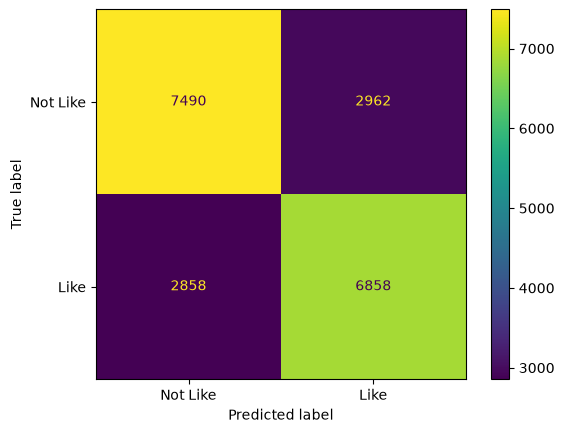

In [121]:
#so now gonna create confusion matrix to see how many predictions were correct and incorrect for each class
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
lr_cm= confusion_matrix(y_test, lr_pred)
ConfusionMatrixDisplay(confusion_matrix=lr_cm, display_labels= ["Not Like", "Like"]).plot();

correct pred= 7490+6858= 14348, total pred= 14348+2962+2858= 20168, accuracy= corr pred/tot pred= 14348/20168= 0.711 so approximately giving 71.14% with what we got earlier. 

### Decision Tree

In [122]:
from sklearn.tree import DecisionTreeClassifier
dt_model= DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred= dt_model.predict(X_test)
print(dt_pred[:10])

[1 1 1 0 0 0 1 1 0 1]


In [123]:
dt_results= pd.DataFrame({"Actual": y_test.values, "Predicted": dt_pred})
display(dt_results.head(10))

,Actual,Predicted
0,0,1
1,1,1
2,1,1
3,0,0
4,0,0
5,0,0
6,1,1
7,1,1
8,0,0
9,1,1


only one out of 10 got worng (line 0) so 90% supportedly correct.

In [124]:
dt_accuracy= accuracy_score(y_test, dt_pred)        
dt_precision= precision_score(y_test, dt_pred)      
dt_recall= recall_score(y_test, dt_pred)            
dt_f1= f1_score(y_test, dt_pred)                    
print("Accuracy:", dt_accuracy)
print("precision:", dt_precision)
print("Recall:", dt_recall)
print("f1 score:", dt_f1)

Accuracy: 0.6394783815946053
precision: 0.6594080062589647
Recall: 0.5204816797035817
f1 score: 0.581765890135174


turned out logistic regression performed better than dicision tree.

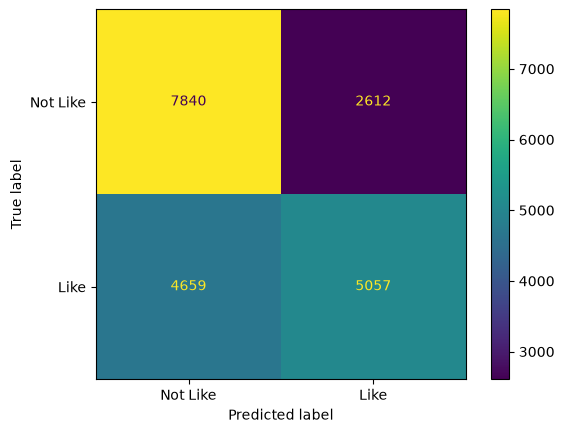

In [125]:
dt_cm= confusion_matrix(y_test, dt_pred)
ConfusionMatrixDisplay(confusion_matrix=dt_cm, display_labels= ["Not Like", "Like"]).plot();

### Navie Bayes

In [126]:
from sklearn.naive_bayes import GaussianNB
nb_model= GaussianNB()
nb_model.fit(X_train, y_train)
nb_pred= nb_model.predict(X_test)
print(nb_pred[:10])

[1 1 1 0 0 0 1 1 0 1]


In [127]:
nb_results= pd.DataFrame({"Actual": y_test.values, "Predicted": nb_pred})
display(nb_results.head(10))

,Actual,Predicted
0,0,1
1,1,1
2,1,1
3,0,0
4,0,0
5,0,0
6,1,1
7,1,1
8,0,0
9,1,1


In [128]:
nb_accuracy= accuracy_score(y_test, nb_pred)        
nb_precision= precision_score(y_test, nb_pred)      
nb_recall= recall_score(y_test, nb_pred)            
nb_f1= f1_score(y_test, nb_pred)                    
print("Accuracy:", nb_accuracy)
print("precision:", nb_precision)
print("Recall:", nb_recall)
print("f1 score:", nb_f1)

Accuracy: 0.6992760809202697
precision: 0.6770095995345681
Recall: 0.7186084808563195
f1 score: 0.697189075840032


Naive Bayes has best recall out of three but overall logistic regression is the best among them.

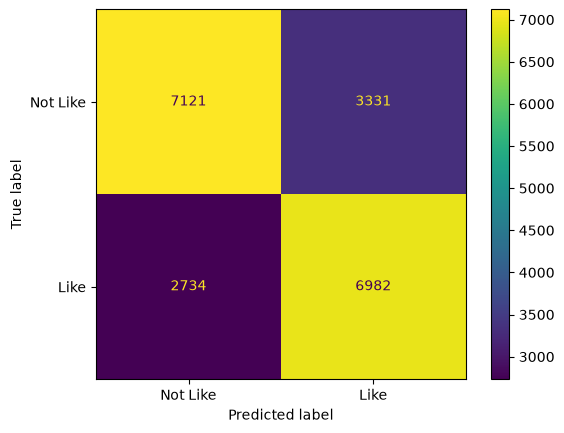

In [129]:
nb_cm= confusion_matrix(y_test, nb_pred)
ConfusionMatrixDisplay(confusion_matrix=nb_cm, display_labels= ["Not Like", "Like"]).plot();

### Comparison

In [130]:
#compare all of them 
model_results= pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Naive Bayes"], 
    "Accuracy": [lr_accuracy, dt_accuracy, nb_accuracy],
    "Precision": [lr_precision, dt_precision, nb_precision],
    "Recall":[lr_recall, dt_recall, nb_recall],
    "f1 score":[lr_f1, dt_f1, nb_f1]
})
display(model_results.round(3))

,Model,Accuracy,Precision,Recall,f1 score
0,Logistic Regression,0.711,0.698,0.706,0.702
1,Decision Tree,0.639,0.659,0.520,0.582
2,Naive Bayes,0.699,0.677,0.719,0.697


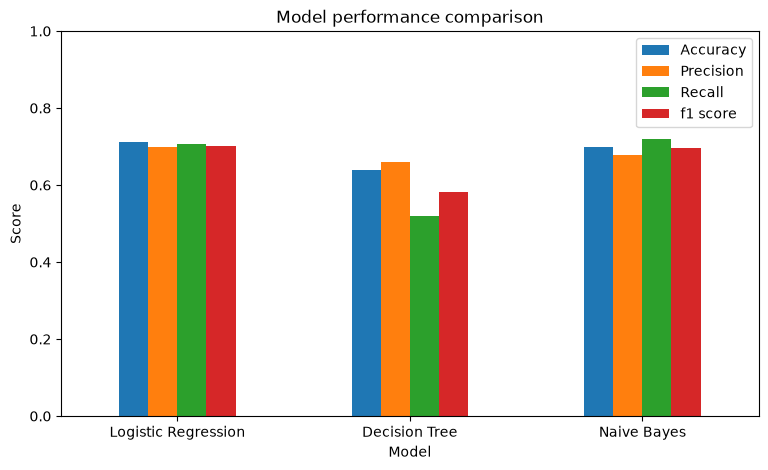

In [131]:
#visualize them
import matplotlib.pyplot as plt
model_results.set_index("Model")[["Accuracy", "Precision", "Recall", "f1 score"]].plot(kind="bar", figsize=(9,5))
plt.ylabel("Score")
plt.title("Model performance comparison")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.show();

In [132]:
#ask each model to predict training data and compare the perfomance with testing performance
lr_train_pred= lr_model.predict(X_train_scaled)
dt_train_pred= dt_model.predict(X_train)
nb_train_pred= nb_model.predict(X_train)
train_results= pd.DataFrame({"Model": ["Logistic Regression", "Decision Tree", "Naive Bayes"],
                             "Accuracy": [accuracy_score(y_train, lr_train_pred),
                                          accuracy_score(y_train, dt_train_pred),
                                          accuracy_score(y_train, nb_train_pred)]})
display(train_results.round(3))

,Model,Accuracy
0,Logistic Regression,0.712
1,Decision Tree,1.000
2,Naive Bayes,0.701


In [133]:
#create simpler decision tree becuase original one is overfitting so we should limit the maax tree depth to 5
dt_model2= DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model2.fit(X_train, y_train)
dt_pred2= dt_model2.predict(X_test)
print("Training accuracy:", accuracy_score(y_train, dt_model2.predict(X_train)))
print("Testing accuracy:", accuracy_score(y_test, dt_pred2))

Training accuracy: 0.7174716120394704
Testing accuracy: 0.707754859182864


In [134]:
#check other as well
dt_accuracy2= accuracy_score(y_test, dt_pred2)        
dt_precision2= precision_score(y_test, dt_pred2)      
dt_recall2= recall_score(y_test, dt_pred2)            
dt_f12= f1_score(y_test, dt_pred2)                    
print("Accuracy:", dt_accuracy2)
print("precision:", dt_precision2)
print("Recall:", dt_recall2)
print("f1 score:", dt_f12)

Accuracy: 0.707754859182864
precision: 0.6887221015208375
Recall: 0.7177850967476328
f1 score: 0.7029533313174076


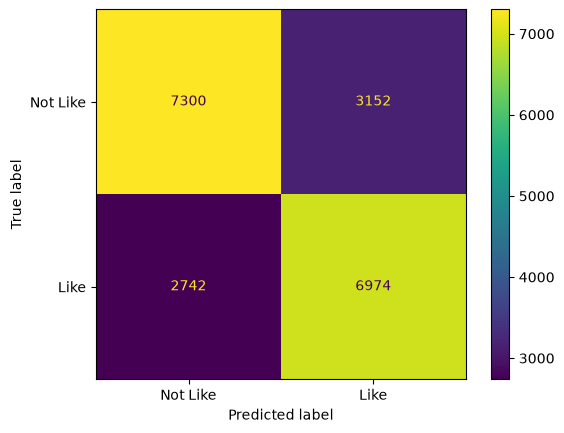

In [135]:
dt_cm2= confusion_matrix(y_test, dt_pred2)
ConfusionMatrixDisplay(confusion_matrix=dt_cm2, display_labels= ["Not Like", "Like"]).plot();

In [136]:
#add this new decision tree to our model_results
model_results.loc[3]=["Decision Tree (depth 5)", dt_accuracy2, dt_precision2, dt_recall2, dt_f12]
display(model_results.round(3))

,Model,Accuracy,Precision,Recall,f1 score
0,Logistic Regression,0.711,0.698,0.706,0.702
1,Decision Tree,0.639,0.659,0.520,0.582
2,Naive Bayes,0.699,0.677,0.719,0.697
3,Decision Tree (depth 5),0.708,0.689,0.718,0.703


results show that LR has highest accuracy, DT2 has highest f1 score, NB has highest recall, DT1 has lowest overall performance.

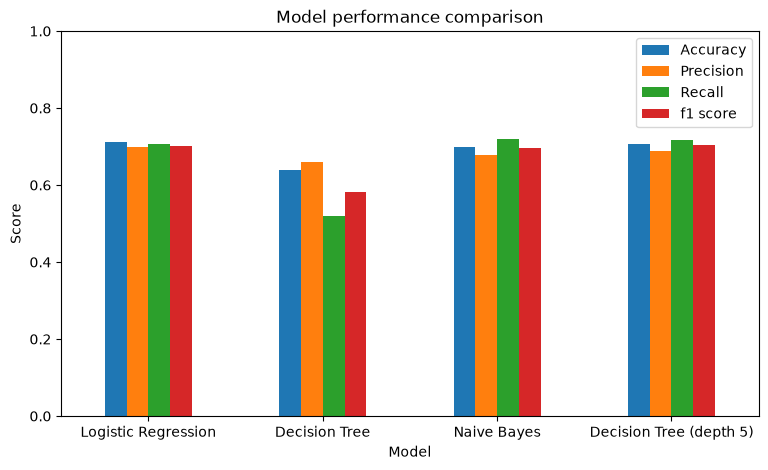

In [137]:
model_results.set_index("Model")[["Accuracy", "Precision", "Recall", "f1 score"]].plot(kind="bar", figsize=(9,5))
plt.ylabel("Score")
plt.title("Model performance comparison")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.show();